# TD4 — Tabular Q-learning — Support

**Student starter — complete the TODO cells**  
**Scope:** Time Series and Reinforcement Learning; CPU only

## Working and claim contract

Local Python 3.11/3.12 with the locked `uv` environment is the primary path. Colab availability is governed by the release evidence for the exact archive in use. Public base seeds are `11, 23, 37, 51, 71`. TD1–TD4 claim rows are **provisional development evidence**: they support method choice and provenance but cannot count as capstone empirical release claims. Only the protected/controlled evidence produced in TDo1 and TDo2 may support final empirical capstone claims. Restart and run top-to-bottom before handoff.

## Support route

Guidance reduces syntax and navigation load; it does not expose the assessed solution or lower the Core standard.

In [1]:
from pathlib import Path
import os, sys

def locate_course_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate/'uv.lock').is_file() and (candidate/'shared').is_dir(): return candidate.resolve()
    for lock in start.glob('*/uv.lock'):
        if (lock.parent/'shared').is_dir(): return lock.parent.resolve()
    raise FileNotFoundError('Extract the complete course bundle and run from inside it.')
COURSE_ROOT=locate_course_root(); os.chdir(COURSE_ROOT)
if str(COURSE_ROOT) not in sys.path: sys.path.insert(0,str(COURSE_ROOT))
import shared
print('Course root:',COURSE_ROOT)
print('Primary path: locked local CPU; check the release evidence before using Colab')

Course root: C:\Users\rapha\Documents\A5\MachineLearning\Advanced_Machine_Learning_ESILV_2026-2027_DVL_final
Primary path: locked local CPU; check the release evidence before using Colab


## Micro-example — exploration and truncation

The declared epsilon path is visible before training. Time-limit truncation still bootstraps. Core trains one Q-table through five seed blocks: this is one training run, not five independent training replicates. Epsilon decays once across all 1,750 episodes and the action RNG is initialized once from the first public seed.

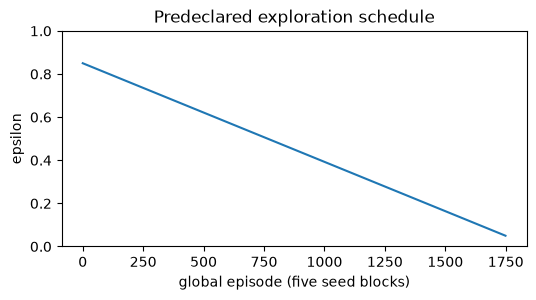

In [2]:
import numpy as np, matplotlib.pyplot as plt
from shared.rl import q_learning_target
assert q_learning_target(-1,5,.9,terminated=True)==-1
assert np.isclose(q_learning_target(-1,5,.9,terminated=False),3.5)
epsilon_curve=np.linspace(.85,.05,1750)
fig,ax=plt.subplots(figsize=(6,2.8)); ax.plot(epsilon_curve); ax.set(xlabel='global episode (five seed blocks)',ylabel='epsilon',title='Predeclared exploration schedule',ylim=(0,1)); plt.show()

## 1 — Restore MDP and separate seeds

In [3]:
import hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from shared.data import PUBLIC_SEEDS
from shared.inventory_env import InventoryControlEnv
from shared.rl import q_learning_target, q_table_policy, random_policy, reorder_policy, evaluate_policies
assert q_learning_target(-1,5,.9,terminated=True)==-1
assert np.isclose(q_learning_target(-1,5,.9,terminated=False),3.5)
development_seeds=tuple(seed+100000 for seed in PUBLIC_SEEDS)
assert set(PUBLIC_SEEDS).isdisjoint(development_seeds)
print('training:',PUBLIC_SEEDS,'development:',development_seeds)

training: (11, 23, 37, 51, 71) development: (100011, 100023, 100037, 100051, 100071)


In [4]:
learning_contract={'q_table_shape':(9,2,3),'alpha':0.18,'gamma':0.96,'epsilon':'linear decay from 0.85 to 0.05 over the 1750 episodes','training':'one Q-table trained through 5 seed blocks x 350 episodes (not 5 independent runs)','episode_seed':'seed*100000 + episode number','action_rng':'one generator default_rng(11), separate from the environment','development_seeds':development_seeds,'truncation':'bootstrap at the 40-day time limit, zero continuation only on a real termination'}
learning_contract

{'q_table_shape': (9, 2, 3),
 'alpha': 0.18,
 'gamma': 0.96,
 'epsilon': 'linear decay from 0.85 to 0.05 over the 1750 episodes',
 'training': 'one Q-table trained through 5 seed blocks x 350 episodes (not 5 independent runs)',
 'episode_seed': 'seed*100000 + episode number',
 'action_rng': 'one generator default_rng(11), separate from the environment',
 'development_seeds': (100011, 100023, 100037, 100051, 100071),
 'truncation': 'bootstrap at the 40-day time limit, zero continuation only on a real termination'}

## 2 — Bounded explicit learning loop

The episode/step structure is supplied. You own the action, target, and update; incomplete code exits without fabricating evidence.

In [5]:
def train_q_learning_student(*,seeds,episodes_per_seed=350,alpha=.18,gamma=.96,epsilon_start=.85,epsilon_end=.05):
    seeds=tuple(int(seed) for seed in seeds); assert seeds and episodes_per_seed>0
    q_table=np.zeros((9,2,3),float); rows=[]; global_episode=0
    total_episodes=len(seeds)*episodes_per_seed
    action_rng=np.random.default_rng(seeds[0])
    for seed in seeds:
        for local_episode in range(episodes_per_seed):
            epsilon=epsilon_start+(epsilon_end-epsilon_start)*(global_episode/max(1,total_episodes-1))
            env=InventoryControlEnv(); observation,_=env.reset(seed=seed*100000+local_episode)
            terminated=truncated=False; episode_cost=0.; action=target=None
            while not (terminated or truncated):
                state=tuple(int(v) for v in observation)
                # TODO 1: epsilon-greedy action using action_rng.
                if action_rng.random() < epsilon:
                    action = int(action_rng.integers(0, 3))
                else:
                    action = int(np.argmax(q_table[state]))
                if action is None: break
                next_observation,reward,terminated,truncated,info=env.step(action)
                next_state=tuple(int(v) for v in next_observation)
                # TODO 2: target bootstraps on truncation; zero continuation only on termination.
                target = q_learning_target(reward, float(np.max(q_table[next_state])), gamma, terminated=terminated)
                if target is None: break
                # TODO 3: alpha-scaled in-place update q_table[state + (action,)].
                q_table[state + (action,)] += alpha * (target - q_table[state + (action,)])
                observation=next_observation; episode_cost+=float(info['cost'])
            env.close()
            if action is None or target is None: return None,None
            rows.append({'seed':seed,'episode':global_episode,'epsilon':epsilon,'episode_cost':episode_cost}); global_episode+=1
    training=pd.DataFrame(rows); assert len(training)==len(seeds)*episodes_per_seed and np.isfinite(q_table).all()
    return q_table,training
q_table,training=train_q_learning_student(seeds=PUBLIC_SEEDS)
print('Trainer pending' if q_table is None else q_table.shape)

(9, 2, 3)


## 3 — Intermediate assertions and explanatory diagnostics

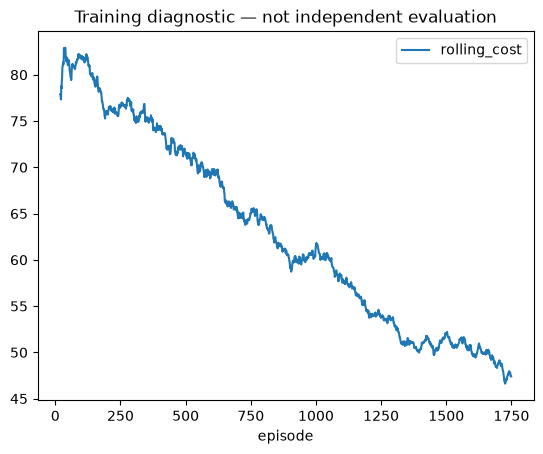

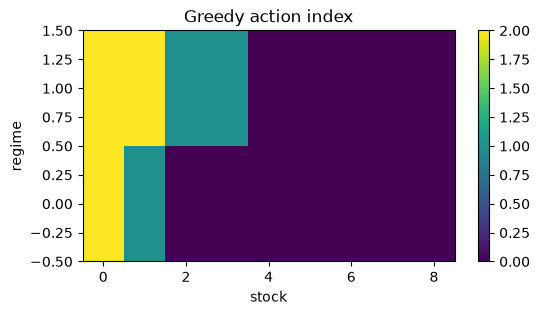

In [6]:
if q_table is not None:
    assert q_table.shape==(9,2,3) and np.isfinite(q_table).all() and len(training)==1750
    training.assign(rolling_cost=training.episode_cost.rolling(100,min_periods=20).mean()).plot(x='episode',y='rolling_cost',title='Training diagnostic — not independent evaluation')
    fig,ax=plt.subplots(figsize=(6,3)); image=ax.imshow(np.argmax(q_table,axis=2).T,aspect='auto',origin='lower'); ax.set(xlabel='stock',ylabel='regime',title='Greedy action index'); fig.colorbar(image,ax=ax); plt.show()
else: print('Diagnostics unlock after the assessed loop is complete.')

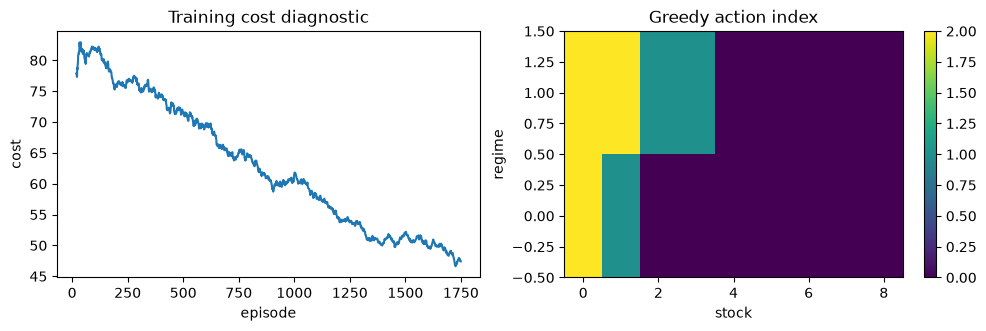

In [7]:
diag_fig,axes=plt.subplots(1,2,figsize=(12,3.2))
axes[0].plot(training.episode,training.episode_cost.rolling(100,min_periods=20).mean())
axes[0].set(title='Training cost diagnostic',xlabel='episode',ylabel='cost')
image=axes[1].imshow(np.argmax(q_table,axis=2).T,aspect='auto',origin='lower')
axes[1].set(title='Greedy action index',xlabel='stock',ylabel='regime'); diag_fig.colorbar(image,ax=axes[1])
plt.show()

### Lecture des diagnostics

- **Courbe de coût** (moyenne glissante sur 100 épisodes) : le coût baisse d'environ 82 au début à environ 47 à la fin, car epsilon diminue et l'agent explore de moins en moins. C'est un diagnostic d'entraînement, **pas** une évaluation : ce sont les épisodes sur lesquels il a appris.
- **Carte de la politique** (action choisie pour chaque stock et période) : en période calme, l'agent recharge 2 à stock 0, 1 à stock 1, puis 0 ; en période chargée, 2 jusqu'au stock 1, 1 aux stocks 2-3, puis 0. C'est presque la règle `reorder` du TD3 (cible 2 en calme, 4 en chargé).

## 4 — Separate development replay and freeze

In [8]:
development_results=pd.DataFrame()
if q_table is not None:
    policies={'random':random_policy,'reorder':reorder_policy,'q_learning':q_table_policy(q_table)}
    development_results=evaluate_policies(policies,seeds=development_seeds)
    assert len(development_results)==15 and development_results.groupby('policy').seed.nunique().eq(5).all()
    output=COURSE_ROOT/'02_labs/TD4_tabular_q_learning/q_table.npy'; np.save(output,q_table,allow_pickle=False)
    print('Q-table SHA256:',hashlib.sha256(output.read_bytes()).hexdigest())
development_results

Q-table SHA256: 61cce1915bd5798f53c22529c9dbdca52b38c2c946a5b186e28e2d777f19738e


,seed,policy,episode_cost,mean_fill_rate,unmet_demand,mean_stock,mean_order_quantity
0,100011,random,71.40,0.850000,9,2.200,1.000
1,100011,reorder,36.45,0.983333,2,0.850,1.125
2,100011,q_learning,36.45,0.983333,2,0.850,1.125
3,100023,random,85.95,0.775000,21,0.525,0.925
4,100023,reorder,40.65,1.000000,0,1.175,1.475
5,100023,q_learning,40.80,0.991667,1,0.975,1.450
6,100037,random,90.15,0.862500,11,3.375,0.925
7,100037,reorder,45.00,0.983333,2,1.600,1.100
8,100037,q_learning,45.00,0.983333,2,1.600,1.100
9,100051,random,105.45,0.687500,26,0.975,0.875


In [9]:
development_results.drop(columns='seed').groupby('policy').mean().round(3)

,episode_cost,mean_fill_rate,unmet_demand,mean_stock,mean_order_quantity
policy,,,,,
q_learning,42.78,0.985,1.8,1.225,1.260
random,87.75,0.812,15.2,2.020,0.995
reorder,42.48,0.988,1.4,1.285,1.270


### Lecture du tableau

Chaque ligne = une stratégie sur 40 jours. Mêmes seeds de développement (100011…100071) = mêmes clients, jamais vus pendant l'entraînement.

| Colonne | Signification | Bon si |
|---|---|---|
| `policy` | `random` = au hasard, `reorder` = règle de bon sens, `q_learning` = Q-table apprise | — |
| `seed` | scénario de clients | — |
| `episode_cost` | coût total sur 40 jours | bas |
| `mean_fill_rate` | part moyenne de la demande servie (1 = 100 %) | proche de 1 |
| `unmet_demand` | cassettes manquées (DAB vide) | proche de 0 |
| `mean_stock` | cassettes qui dorment dans le DAB | bas |
| `mean_order_quantity` | cassettes rechargées par jour | — |

On juge sur le coût **et** le service ensemble.

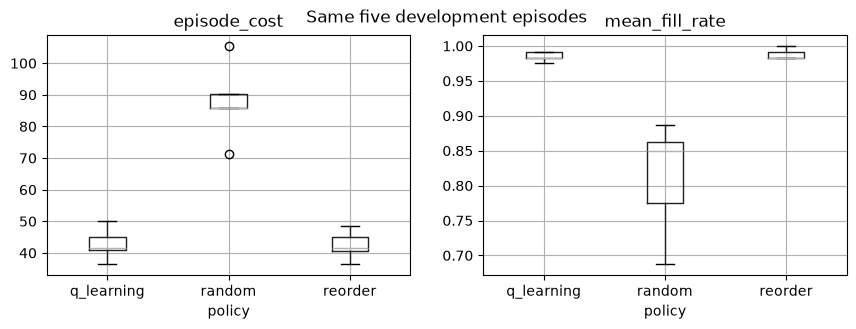

In [10]:
fig,axes=plt.subplots(1,2,figsize=(10,3.2))
development_results.boxplot(column='episode_cost',by='policy',ax=axes[0])
development_results.boxplot(column='mean_fill_rate',by='policy',ax=axes[1])
fig.suptitle('Same five development episodes'); plt.show()

## Required interpretation

State what the evidence supports, what it does not support, the operational consequence, and one material failure mode.

In [11]:
# TODO: replace with 4–6 evidence-backed sentences.
interpretation='We can observe that the Q-learning policy beats the random policy but does not beat the reorder strategy.' \
' On the 5 development seeds that were never used for training, Q-learning costs 42.78 on average vs 42.48 for reorder and 87.75 for random, fill rate is 98.5% vs 98.8% vs 81.2% and unmet demand is 1.8 vs 1.4 vs 15.2. ' \
'The policy map shows that the agent learned almost the same rule as the reorder strategy (around 2 cassettes in low demand and 4 in high demand), so the small gap is not a real improvement. ' \
'The training curve goes down from about 82 to 47, but it is only a diagnostic because the agent learned on those episodes. ' \
'However, it does not prove that Q-learning would work on a real ATM: it is one training run and 5 simulated episodes.' \
' Operationally, the bank should keep the reorder strategy, which is as good and easier to explain, and keep the Q-table only for the controlled evaluation of TDo2.' \
' The main risk is that the Q-table is only valid for this simulator: if real costs or demand change, it has to be trained again, while the reorder rule can be adjusted by hand.'
print(interpretation or 'Interpretation pending.')

We can observe that the Q-learning policy beats the random policy but does not beat the reorder strategy. On the 5 development seeds that were never used for training, Q-learning costs 42.78 on average vs 42.48 for reorder and 87.75 for random, fill rate is 98.5% vs 98.8% vs 81.2% and unmet demand is 1.8 vs 1.4 vs 15.2. The policy map shows that the agent learned almost the same rule as the reorder strategy (around 2 cassettes in low demand and 4 in high demand), so the small gap is not a real improvement. The training curve goes down from about 82 to 47, but it is only a diagnostic because the agent learned on those episodes. However, it does not prove that Q-learning would work on a real ATM: it is one training run and 5 simulated episodes. Operationally, the bank should keep the reorder strategy, which is as good and easier to explain, and keep the Q-table only for the controlled evaluation of TDo2. The main risk is that the Q-table is only valid for this simulator: if real costs or

## Evidence freeze — export to the portfolio

In [12]:
import json, shutil, sys, platform
out=COURSE_ROOT.parent/'ML_Portfolio_Chennouf_Cebe'/'evidence/td4'; out.mkdir(parents=True,exist_ok=True)
shutil.copy(output,out/'q_table.npy')
training.to_csv(out/'td4_training_trace.csv',index=False)
development_results.to_csv(out/'td4_development_results.csv',index=False)
pd.DataFrame(np.argmax(q_table,axis=2),columns=['low_regime','high_regime']).rename_axis('stock').to_csv(out/'td4_greedy_policy.csv')
fig.savefig(out/'td4_boxplot.png',dpi=120,bbox_inches='tight')
diag_fig.savefig(out/'td4_training_diagnostics.png',dpi=120,bbox_inches='tight')
json.dump({**learning_contract,'q_table_shape':list(q_table.shape),'development_seeds':list(development_seeds),
           'training_seeds':list(PUBLIC_SEEDS),'episodes':len(training),
           'q_table_sha256':hashlib.sha256((out/'q_table.npy').read_bytes()).hexdigest(),
           'environment_sha256':hashlib.sha256((COURSE_ROOT/'shared/inventory_env.py').read_bytes()).hexdigest(),
           'python':sys.version.split()[0],'numpy':np.__version__,'pandas':pd.__version__,'platform':platform.platform(),
           'status':'development_only'},open(out/'td4_config.json','w'),indent=2)
print(sorted(p.name for p in out.iterdir()))

['q_table.npy', 'td4_boxplot.png', 'td4_config.json', 'td4_development_results.csv', 'td4_greedy_policy.csv', 'td4_training_diagnostics.png', 'td4_training_trace.csv']


## Optional Extension — ungraded

Freeze valid Core first. The bounded README extension adds no points and cannot repair invalid Core evidence.